<class 'pandas.DataFrame'>
RangeIndex: 548 entries, 0 to 547
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MarketID          548 non-null    int64  
 1   MarketSize        548 non-null    str    
 2   LocationID        548 non-null    int64  
 3   AgeOfStore        548 non-null    int64  
 4   Promotion         548 non-null    int64  
 5   week              548 non-null    int64  
 6   SalesInThousands  548 non-null    float64
dtypes: float64(1), int64(5), str(1)
memory usage: 30.1 KB
None
         MarketID  LocationID  AgeOfStore   Promotion        week  \
count  548.000000  548.000000  548.000000  548.000000  548.000000   
mean     5.715328  479.656934    8.503650    2.029197    2.500000   
std      2.877001  287.973679    6.638345    0.810729    1.119055   
min      1.000000    1.000000    1.000000    1.000000    1.000000   
25%      3.000000  216.000000    4.000000    1.000000    1.750000   
50%   

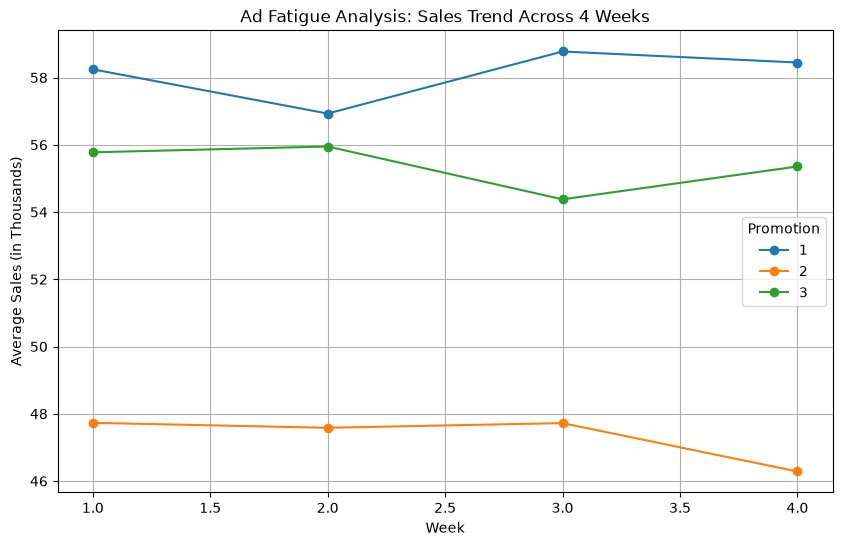

Promotion               1          2          3
Store_Category                                 
New             67.666458  47.650179  66.704286
Established     54.884559  47.127361  51.078587
Mature          53.801607  47.272500  56.493676
                 mean                            sum                   count  \
Promotion           1          2          3        1        2        3     1   
MarketSize                                                                     
Large       75.235893  60.322031  77.203958  4213.21  3860.61  3705.79    56   
Medium      47.672604  39.114352  45.468879  4576.57  4224.35  5274.39    96   
Small       60.162500  50.810625  59.514167  1203.25   812.97  1428.34    20   

                      
Promotion     2    3  
MarketSize            
Large        64   48  
Medium      108  116  
Small        16   24  


C:\Users\lenovo\AppData\Local\Temp\ipykernel_21420\483720456.py:51: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


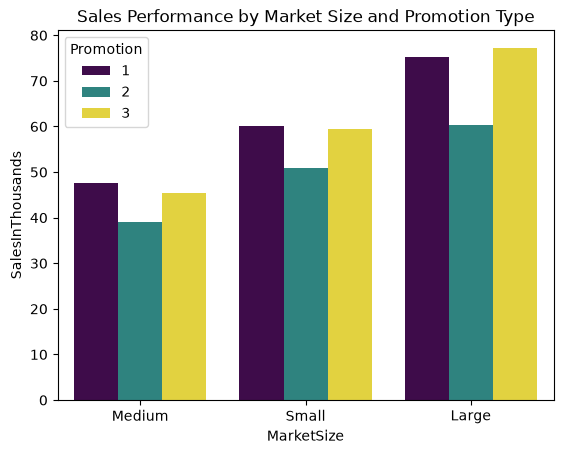

                Mean  Median    Std_Dev       CV_%
Promotion                                         
1          58.099012  55.385  16.553782  28.492364
2          47.329415  45.385  15.108955  31.922970
3          55.364468  51.165  16.766231  30.283377
ANOVA F-value: 21.953485793080674, P-value: 6.765849261408834e-10


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Reading Data
df = pd.read_csv('C:/Users/lenovo/Downloads/WA_Marketing-Campaign.csv')

# A quick look at the key data
print(df.info())
print(df.describe())

# Calculating average sales per campaign by week
ad_fatigue = (
    df.groupby(['Promotion', 'week'])['SalesInThousands'].mean().unstack()
)
print(ad_fatigue)

# Chart for tracking weekly sales trends
ad_fatigue.T.plot(kind='line', marker='o', figsize=(10, 6))
plt.title('Ad Fatigue Analysis: Sales Trend Across 4 Weeks')
plt.xlabel('Week')
plt.ylabel('Average Sales (in Thousands)')
plt.grid(True)
plt.show()

# Dividing stores into categories (e.g., new <= 3 years, established 4-9, mature > 9 years)
df['Store_Category'] = pd.cut(
    df['AgeOfStore'],
    bins=[-1, 3, 9, 30],
    labels=['New', 'Established', 'Mature'],
)

# Sales analysis by store category and campaign type
synergy = (
    df.groupby(['Store_Category', 'Promotion'])['SalesInThousands']
    .mean()
    .unstack()
)
print(synergy)

# Comparing campaign performance across different market sizes
market_promo = (
    df.groupby(['MarketSize', 'Promotion'])['SalesInThousands']
    .agg(['mean', 'sum', 'count'])
    .unstack()
)
print(market_promo)

# Chart for visualizing the interaction
sns.barplot(
    x='MarketSize',
    y='SalesInThousands',
    hue='Promotion',
    data=df,
    ci=None,
    palette='viridis',
)
plt.title('Sales Performance by Market Size and Promotion Type')
plt.show()

# Measuring stability and risk for each campaign
risk_analysis = df.groupby('Promotion')['SalesInThousands'].agg(
    ['mean', 'median', 'std', lambda x: x.std() / x.mean() * 100]
)
risk_analysis.columns = ['Mean', 'Median', 'Std_Dev', 'CV_%']
print(risk_analysis)

import scipy.stats as stats

# Sales breakdown by campaign
group1 = df[df['Promotion'] == 1]['SalesInThousands']
group2 = df[df['Promotion'] == 2]['SalesInThousands']
group3 = df[df['Promotion'] == 3]['SalesInThousands']

# Performing an ANOVA test
f_val, p_val = stats.f_oneway(group1, group2, group3)
print(f'ANOVA F-value: {f_val}, P-value: {p_val}')